# 5. Tables and figures
Summary tables and all figures of the paper.

Run the notebooks 1 to 4 first. The figures use the font Liberation Sans if it is installed (`apt-get install -y fonts-liberation`), otherwise DejaVu Sans.

In [1]:
import torch
import pandas as pd

from constants import *
from utils import get_device
from dataset import load_pieces, get_duration_values
from disk_utils import load_results
from faithfulness import load_deletion_tests
from attention_inspector import AttentionInspector
from plot_manager import PlotManager
from result_tables import (
    per_seed_table,
    summary_table,
    paired_tests,
    pooled_report,
    list_confusions,
    group_errors,
    write_summary_files
)

In [2]:
USE_GPU = True
device = get_device(USE_GPU)
print(device)

# QUICK_TEST = True reads the dry run in results_quick_test/ and writes
# the figures to figs_quick_test/.
QUICK_TEST = False

if QUICK_TEST:
    results_dir = QUICK_TEST_RESULTS_DIR
    figs_dir = QUICK_TEST_FIGS_DIR
else:
    results_dir = RESULTS_DIR
    figs_dir = FIGS_DIR

# set to False to look at the figures without writing the files
SAVE_FIGS = True

cpu


## Tables

All accuracies as text files: `summary.txt`, `full_pooled.txt`, `paired_tests.txt`.

In [3]:
write_summary_files(results_dir)

Wrote summary.txt, full_pooled.txt and paired_tests.txt to results/


Mean ± 95% CI over the five splits (Tables 4 and 7).

In [4]:
results = load_results(results_dir)
per_seed = per_seed_table(results)
summary = summary_table(per_seed)

pd.set_option("display.max_rows", 200)
summary[["tag", "perturbation", "n", "acc_mean", "acc_ci", "f1_mean", "f1_ci"]]

,tag,perturbation,n,acc_mean,acc_ci,f1_mean,f1_ci
0,bigram__logreg,,5,0.900571,0.008090,0.896318,0.010570
1,bigram__svm_rbf,,5,0.915429,0.019038,0.912351,0.022586
2,full,,5,0.920000,0.029254,0.914877,0.031895
3,full,shuffle,5,0.801143,0.023745,0.796994,0.025061
4,full,transpose+13,5,0.169143,0.049311,0.080260,0.033280
5,full,transpose+4,5,0.030857,0.016334,0.015126,0.012548
6,full,transpose+5,5,0.101714,0.020318,0.047696,0.022938
7,full,transpose+9,5,0.056000,0.038667,0.017423,0.011787
8,full,transpose-13,5,0.068571,0.012289,0.015989,0.005624
9,full,transpose-4,5,0.070857,0.048797,0.042353,0.035360


Paired comparison with the proposed model (the Δ and p columns of Tables 4 and 7).

In [5]:
paired_tests(per_seed, reference_tag="full")

,tag,perturbation,n_splits,acc_mean,delta_points,p_paired_t,all_splits_same_sign
0,bigram__logreg,,5,90.057143,-1.942857,8.172591e-02,False
1,bigram__svm_rbf,,5,91.542857,-0.457143,7.205095e-01,False
2,full,shuffle,5,80.114286,-11.885714,1.554355e-04,True
3,full,transpose+13,5,16.914286,-75.085714,1.116857e-06,True
4,full,transpose+4,5,3.085714,-88.914286,3.273929e-07,True
5,full,transpose+5,5,10.171429,-81.828571,1.260382e-08,True
6,full,transpose+9,5,5.600000,-86.400000,3.316869e-06,True
7,full,transpose-13,5,6.857143,-85.142857,3.286510e-07,True
8,full,transpose-4,5,7.085714,-84.914286,1.831238e-07,True
9,full,transpose-5,5,10.857143,-81.142857,4.596287e-06,True


Per-makam precision, recall and F1 of the proposed model, pooled over the five test subsets (Table 5).

In [6]:
# the unperturbed runs of the proposed model
main_results = []
for result in load_results(results_dir, "full"):
    if not result.get("perturbation"):
        main_results.append(result)

report, cm = pooled_report(main_results)
report.round(2)

,precision,recall,f1-score,support
hicaz,0.99,0.99,0.99,120.00
nihavent,0.98,0.98,0.98,100.00
ussak,0.90,0.83,0.87,90.00
rast,0.90,0.95,0.93,85.00
huzzam,0.94,0.94,0.94,70.00
segah,0.94,0.91,0.93,70.00
huseyni,0.77,0.66,0.71,70.00
mahur,0.93,0.97,0.95,65.00
hicazkar,0.98,0.98,0.98,60.00
kurdilihicazkar,0.98,0.96,0.97,50.00


Confusions of the proposed model, most frequent first (Table 6).

In [7]:
for true_makam, predicted_makam, count in list_confusions(cm):
    if count >= 2:
        print(f"{true_makam:>16s} -> {predicted_makam:<16s} {count}")

         huseyni -> muhayyer         15
           ussak -> huseyni          7
           ussak -> muhayyer         5
         huseyni -> ussak            5
        muhayyer -> huseyni          5
          huzzam -> segah            4
           segah -> huzzam           3
         huseyni -> rast             3
           ussak -> rast             2
            rast -> mahur            2
           segah -> rast             2
            saba -> ussak            2


Errors inside the group Uşşak–Hüseyni–Muhayyer and between Segah and Hüzzam, for every model.

In [8]:
group_errors(results)

,tag,errors,within_group,segah_huzzam,recall_huseyni,recall_muhayyer
0,bigram__logreg,87,41,9,0.614286,0.72
1,bigram__svm_rbf,74,36,9,0.700000,0.78
2,full,70,38,7,0.657143,0.86
3,full_unpacked,73,40,9,0.585714,0.80
4,hist53_cnt__knn,119,57,11,0.500000,0.44
5,hist53_cnt__logreg,93,41,6,0.714286,0.50
6,hist53_cnt__rf,102,46,7,0.628571,0.54
7,hist53_cnt__svm_rbf,90,43,10,0.671429,0.60
8,hist53_dur__knn,100,54,10,0.671429,0.50
9,hist53_dur__logreg,66,34,7,0.814286,0.66


## Figures

In [9]:
pm = PlotManager(figs_dir=figs_dir)

pieces, labels, vocab = load_pieces()
dur_values = get_duration_values(vocab)

Figure 1: pieces per makam

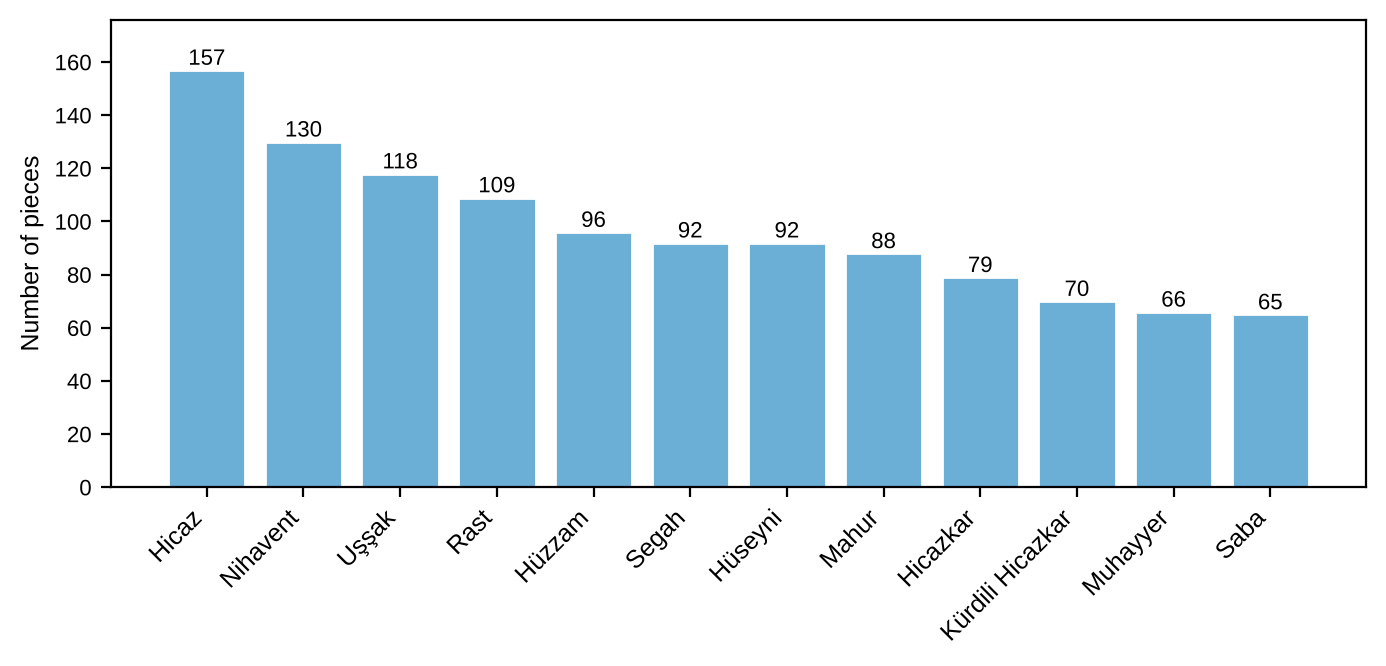

In [10]:
pm.plot_makam_distribution(labels, save_fig=SAVE_FIGS)

Figure 2: notes per piece

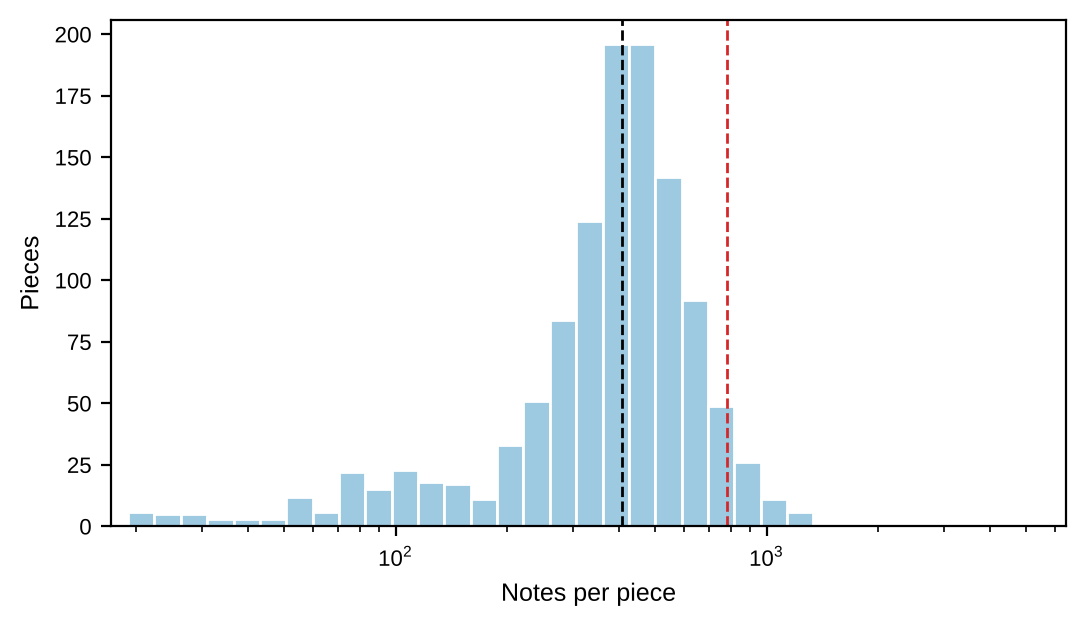

Lengths | min: 19, median: 407.5, mean: 422.1, 95th percentile: 783.9, max: 5832


In [11]:
pm.plot_length_histogram(pieces, save_fig=SAVE_FIGS)

Figure 4: overview of all accuracies

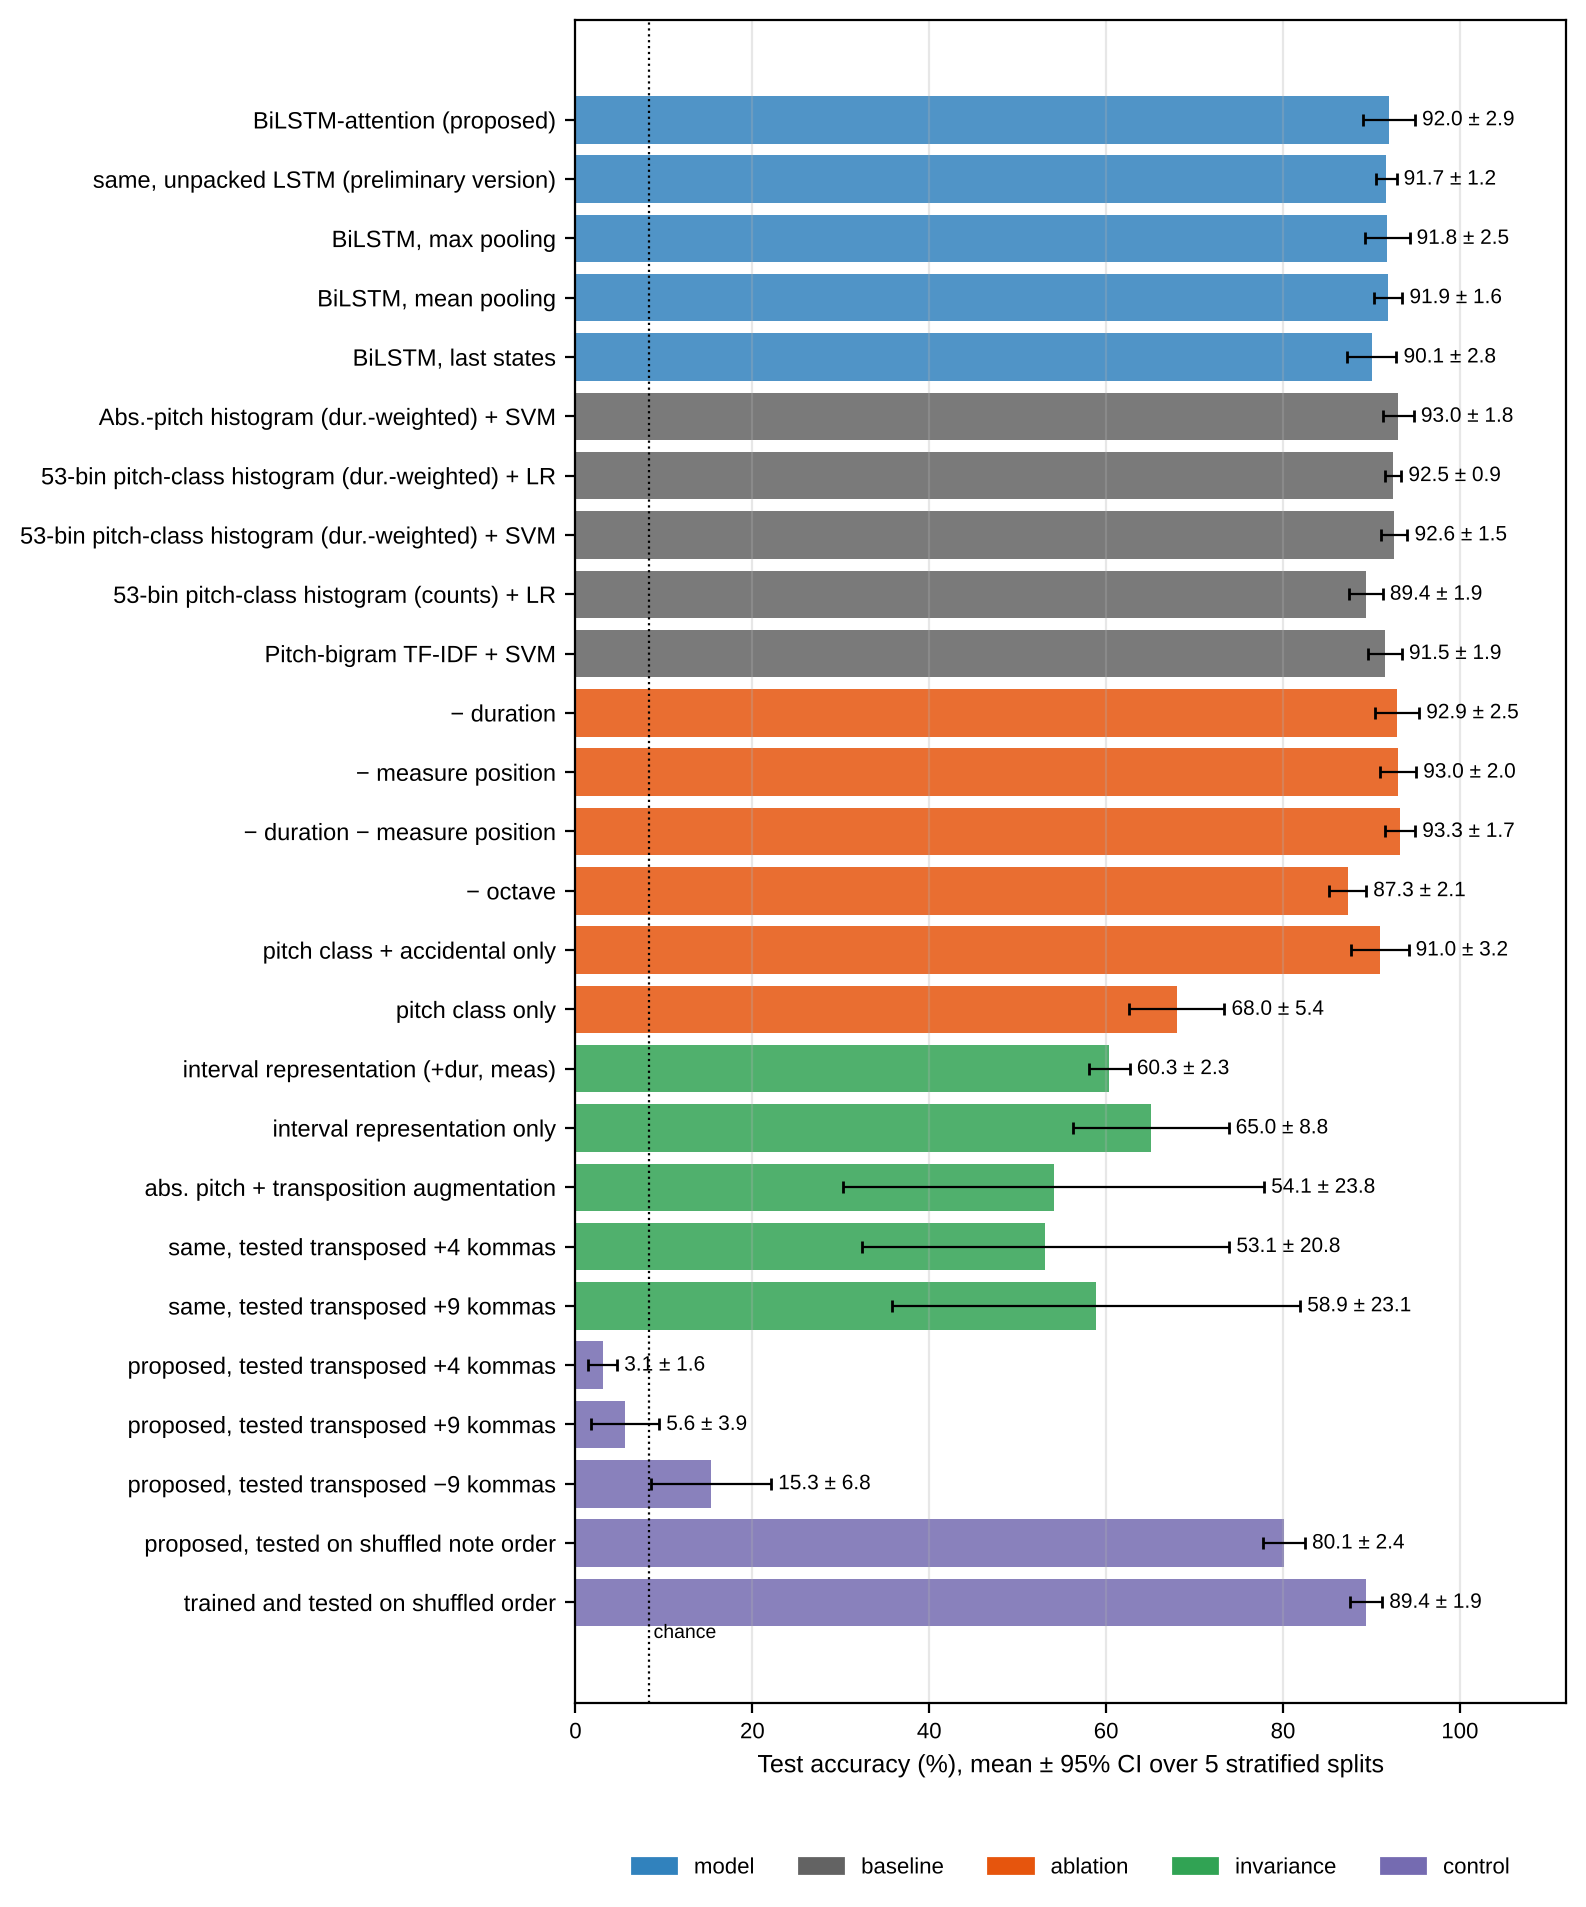

In [12]:
pm.plot_results_overview(summary, save_fig=SAVE_FIGS)

Figure 5: confusion matrix of the proposed model

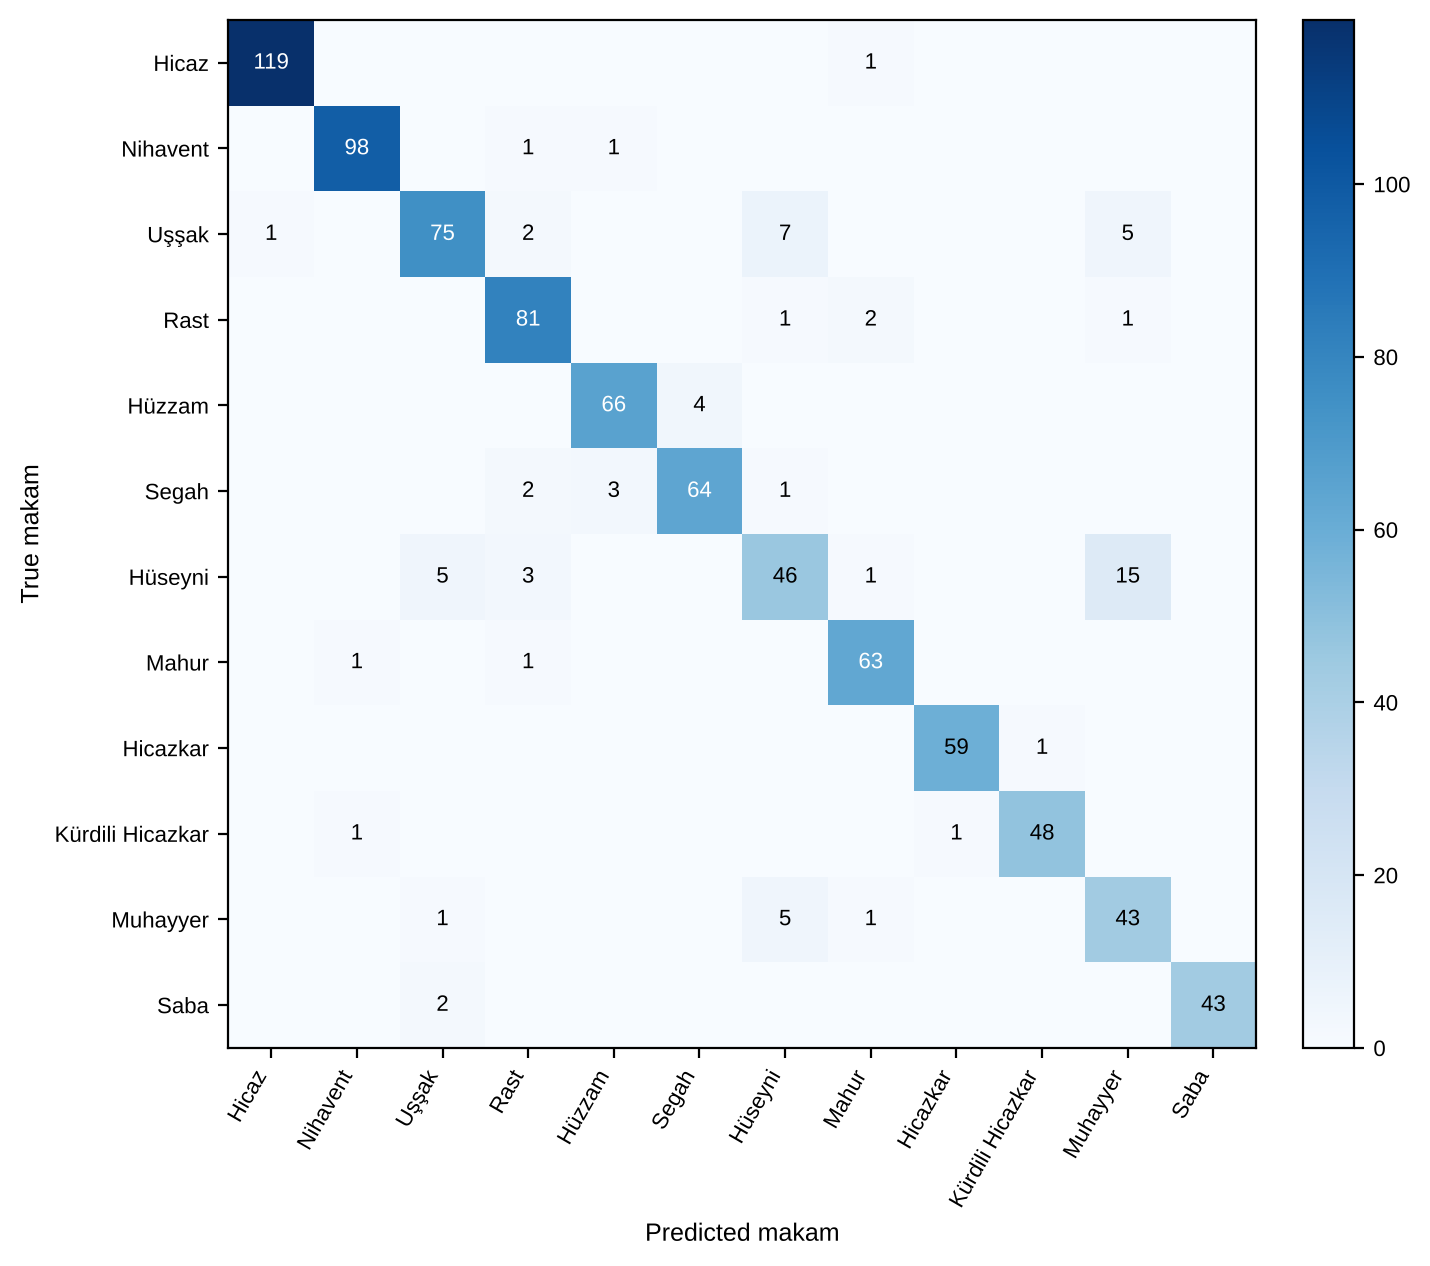

In [13]:
pm.plot_confusion_matrix(cm.values, save_fig=SAVE_FIGS)

Figure 6: deletion tests

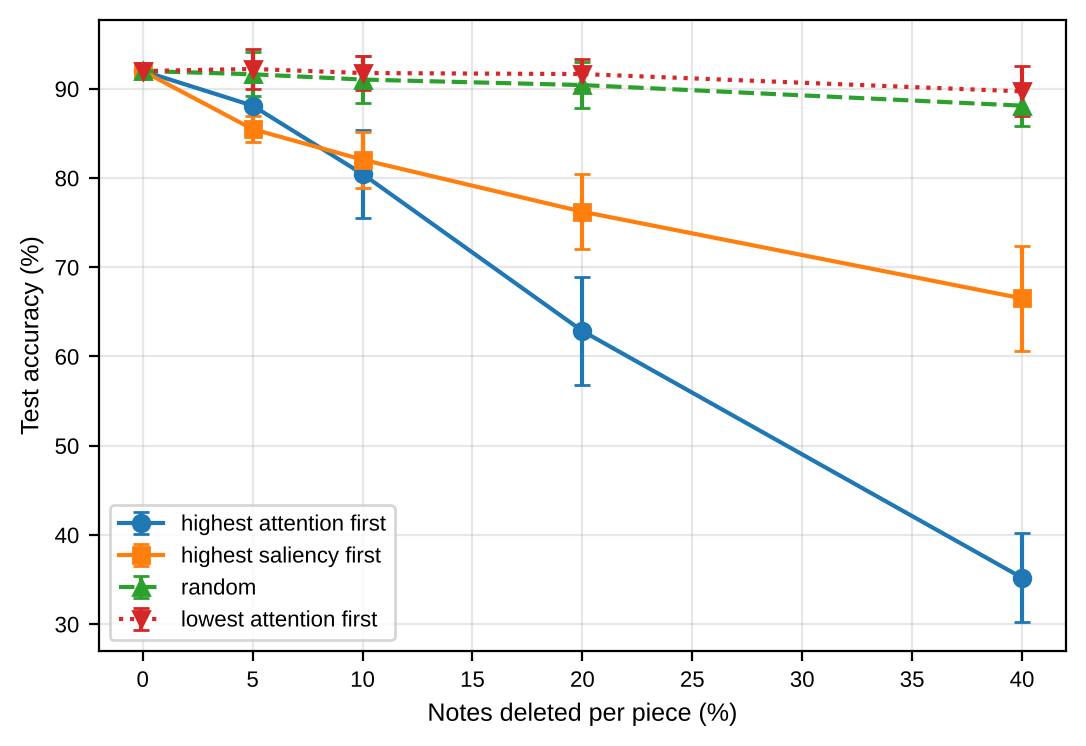

In [14]:
curves, deletion_summary = load_deletion_tests("full", results_dir)
pm.plot_deletion_curves(curves, deletion_summary, tag="full", save_fig=SAVE_FIGS)

Figure 7 and Figure C1: pitch enrichment per makam, ordered by frequency and by pitch

In [15]:
ai = AttentionInspector(device, results_dir=results_dir)

note_table = ai.load_note_table("full")
enrichment = ai.pitch_enrichment(note_table)

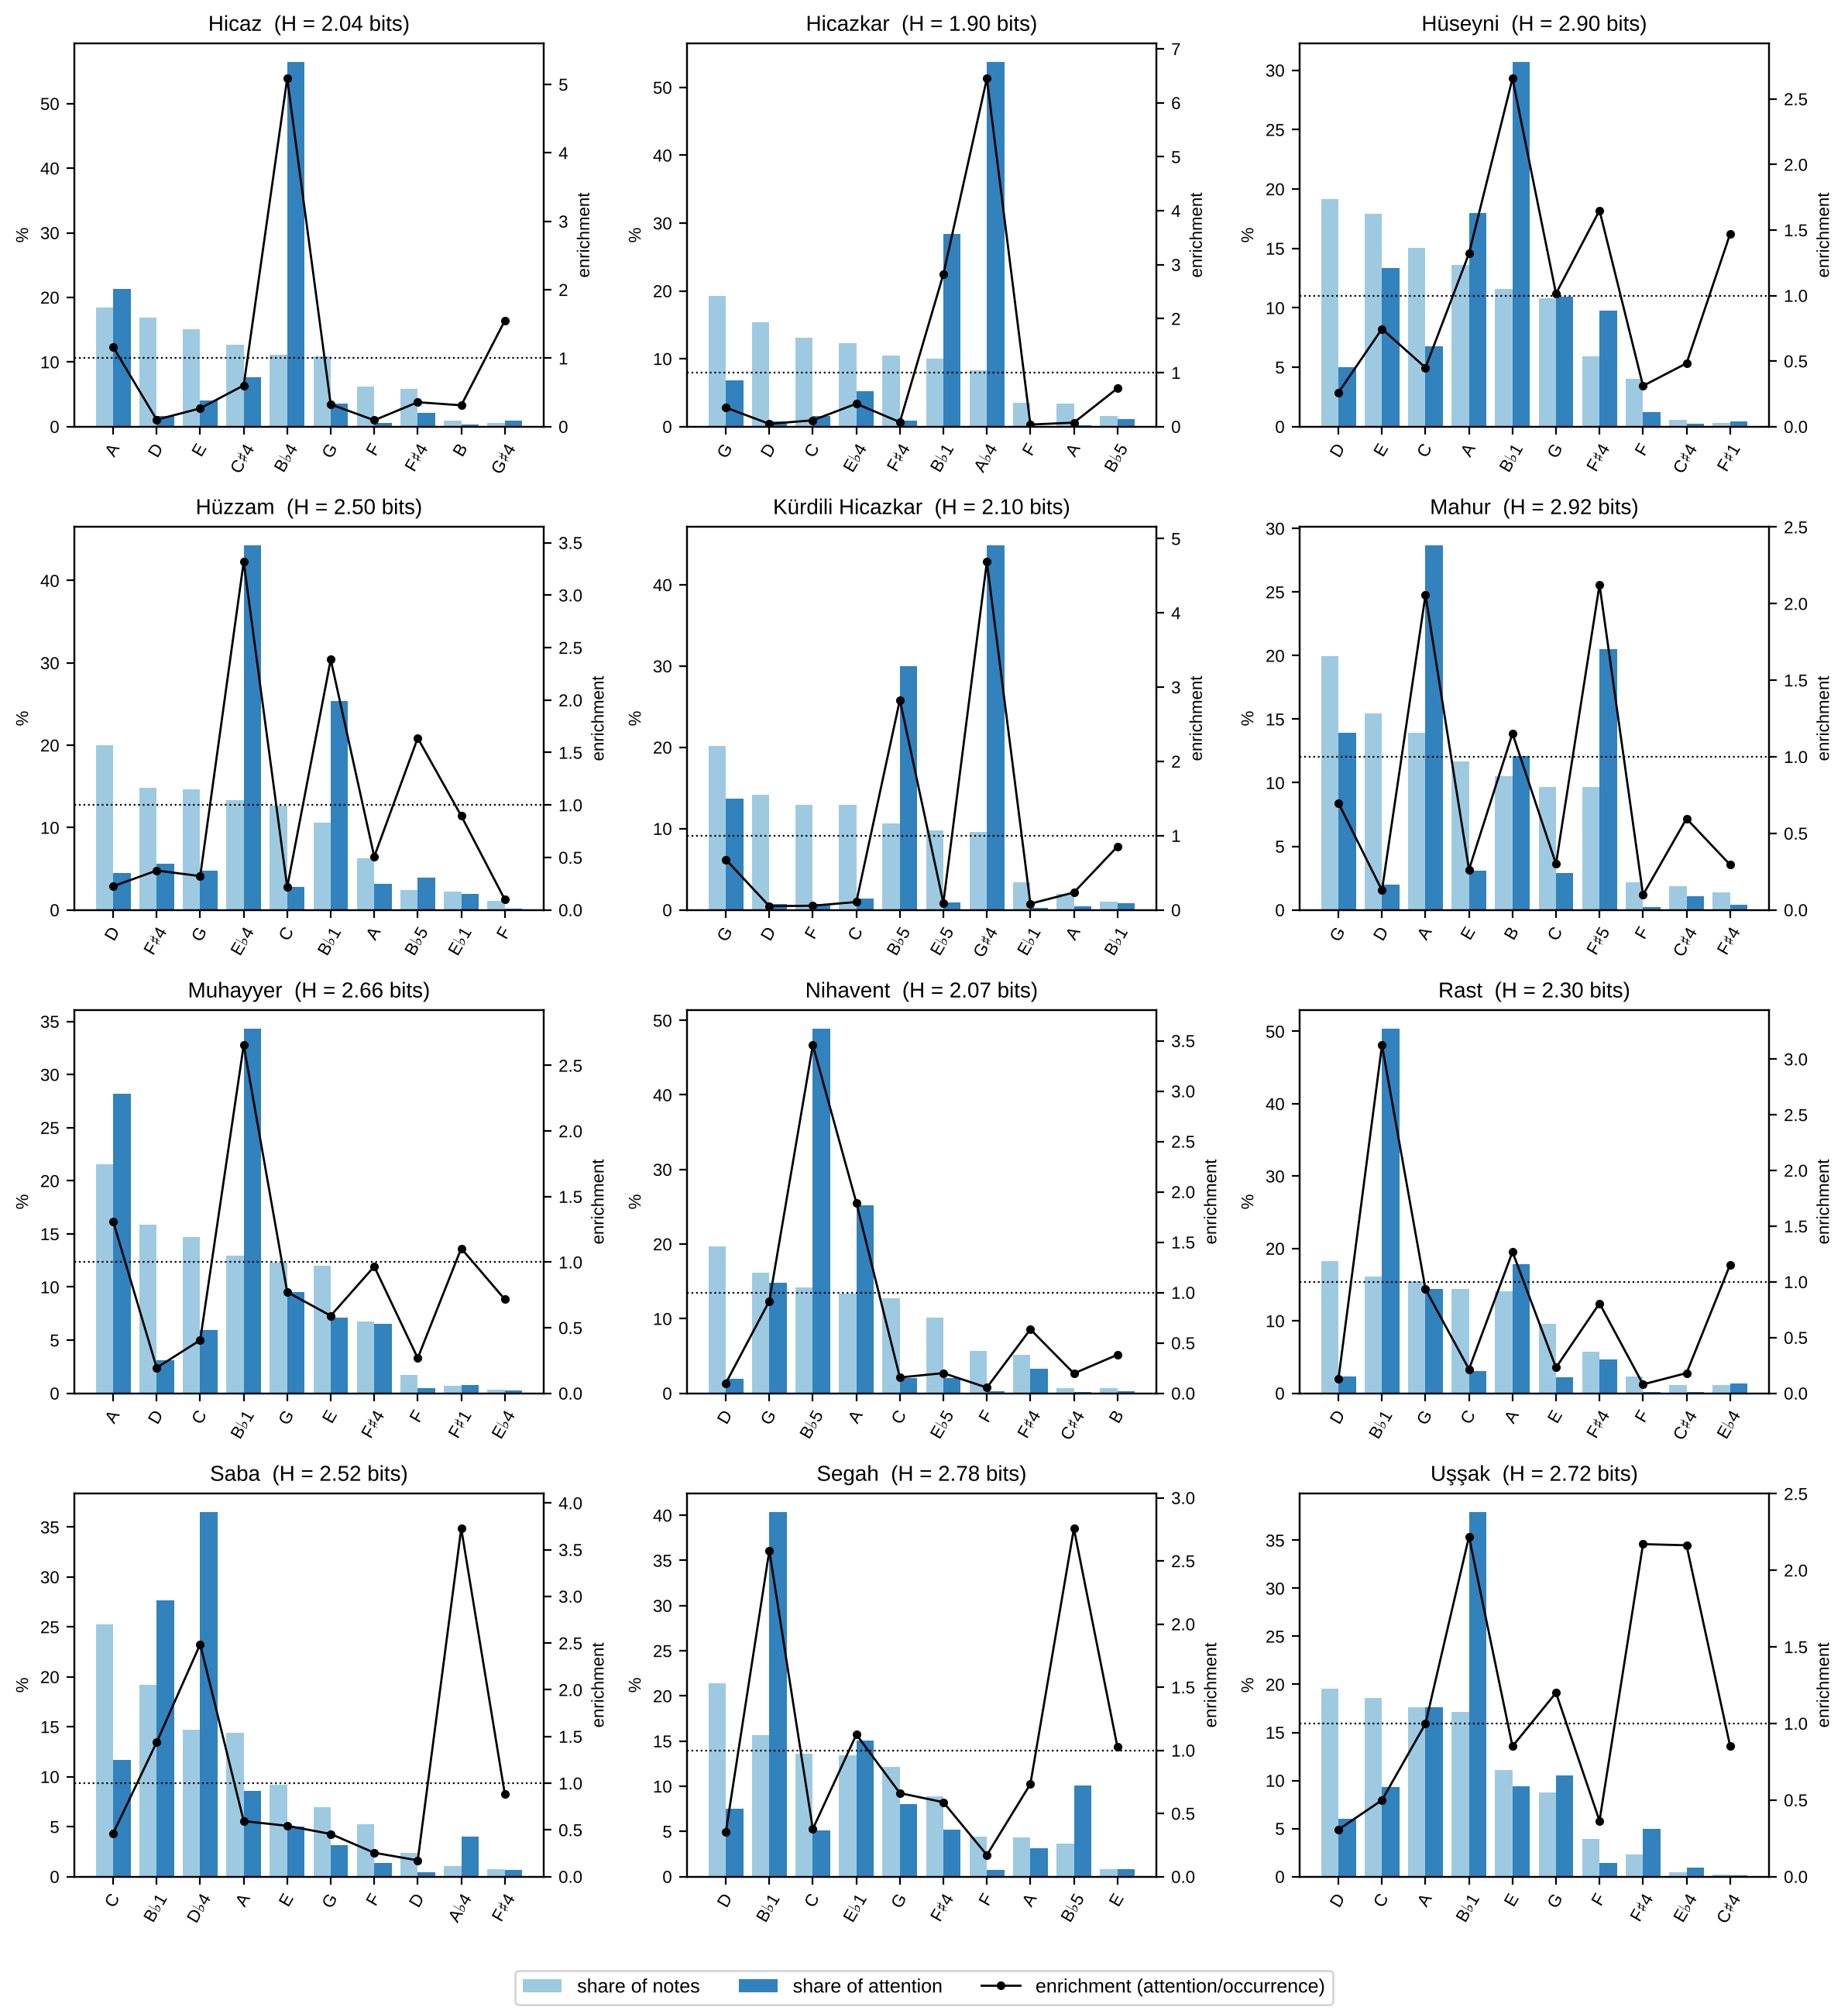

In [16]:
pm.plot_pitch_enrichment(enrichment, tag="full", pitch_order=False, save_fig=SAVE_FIGS)

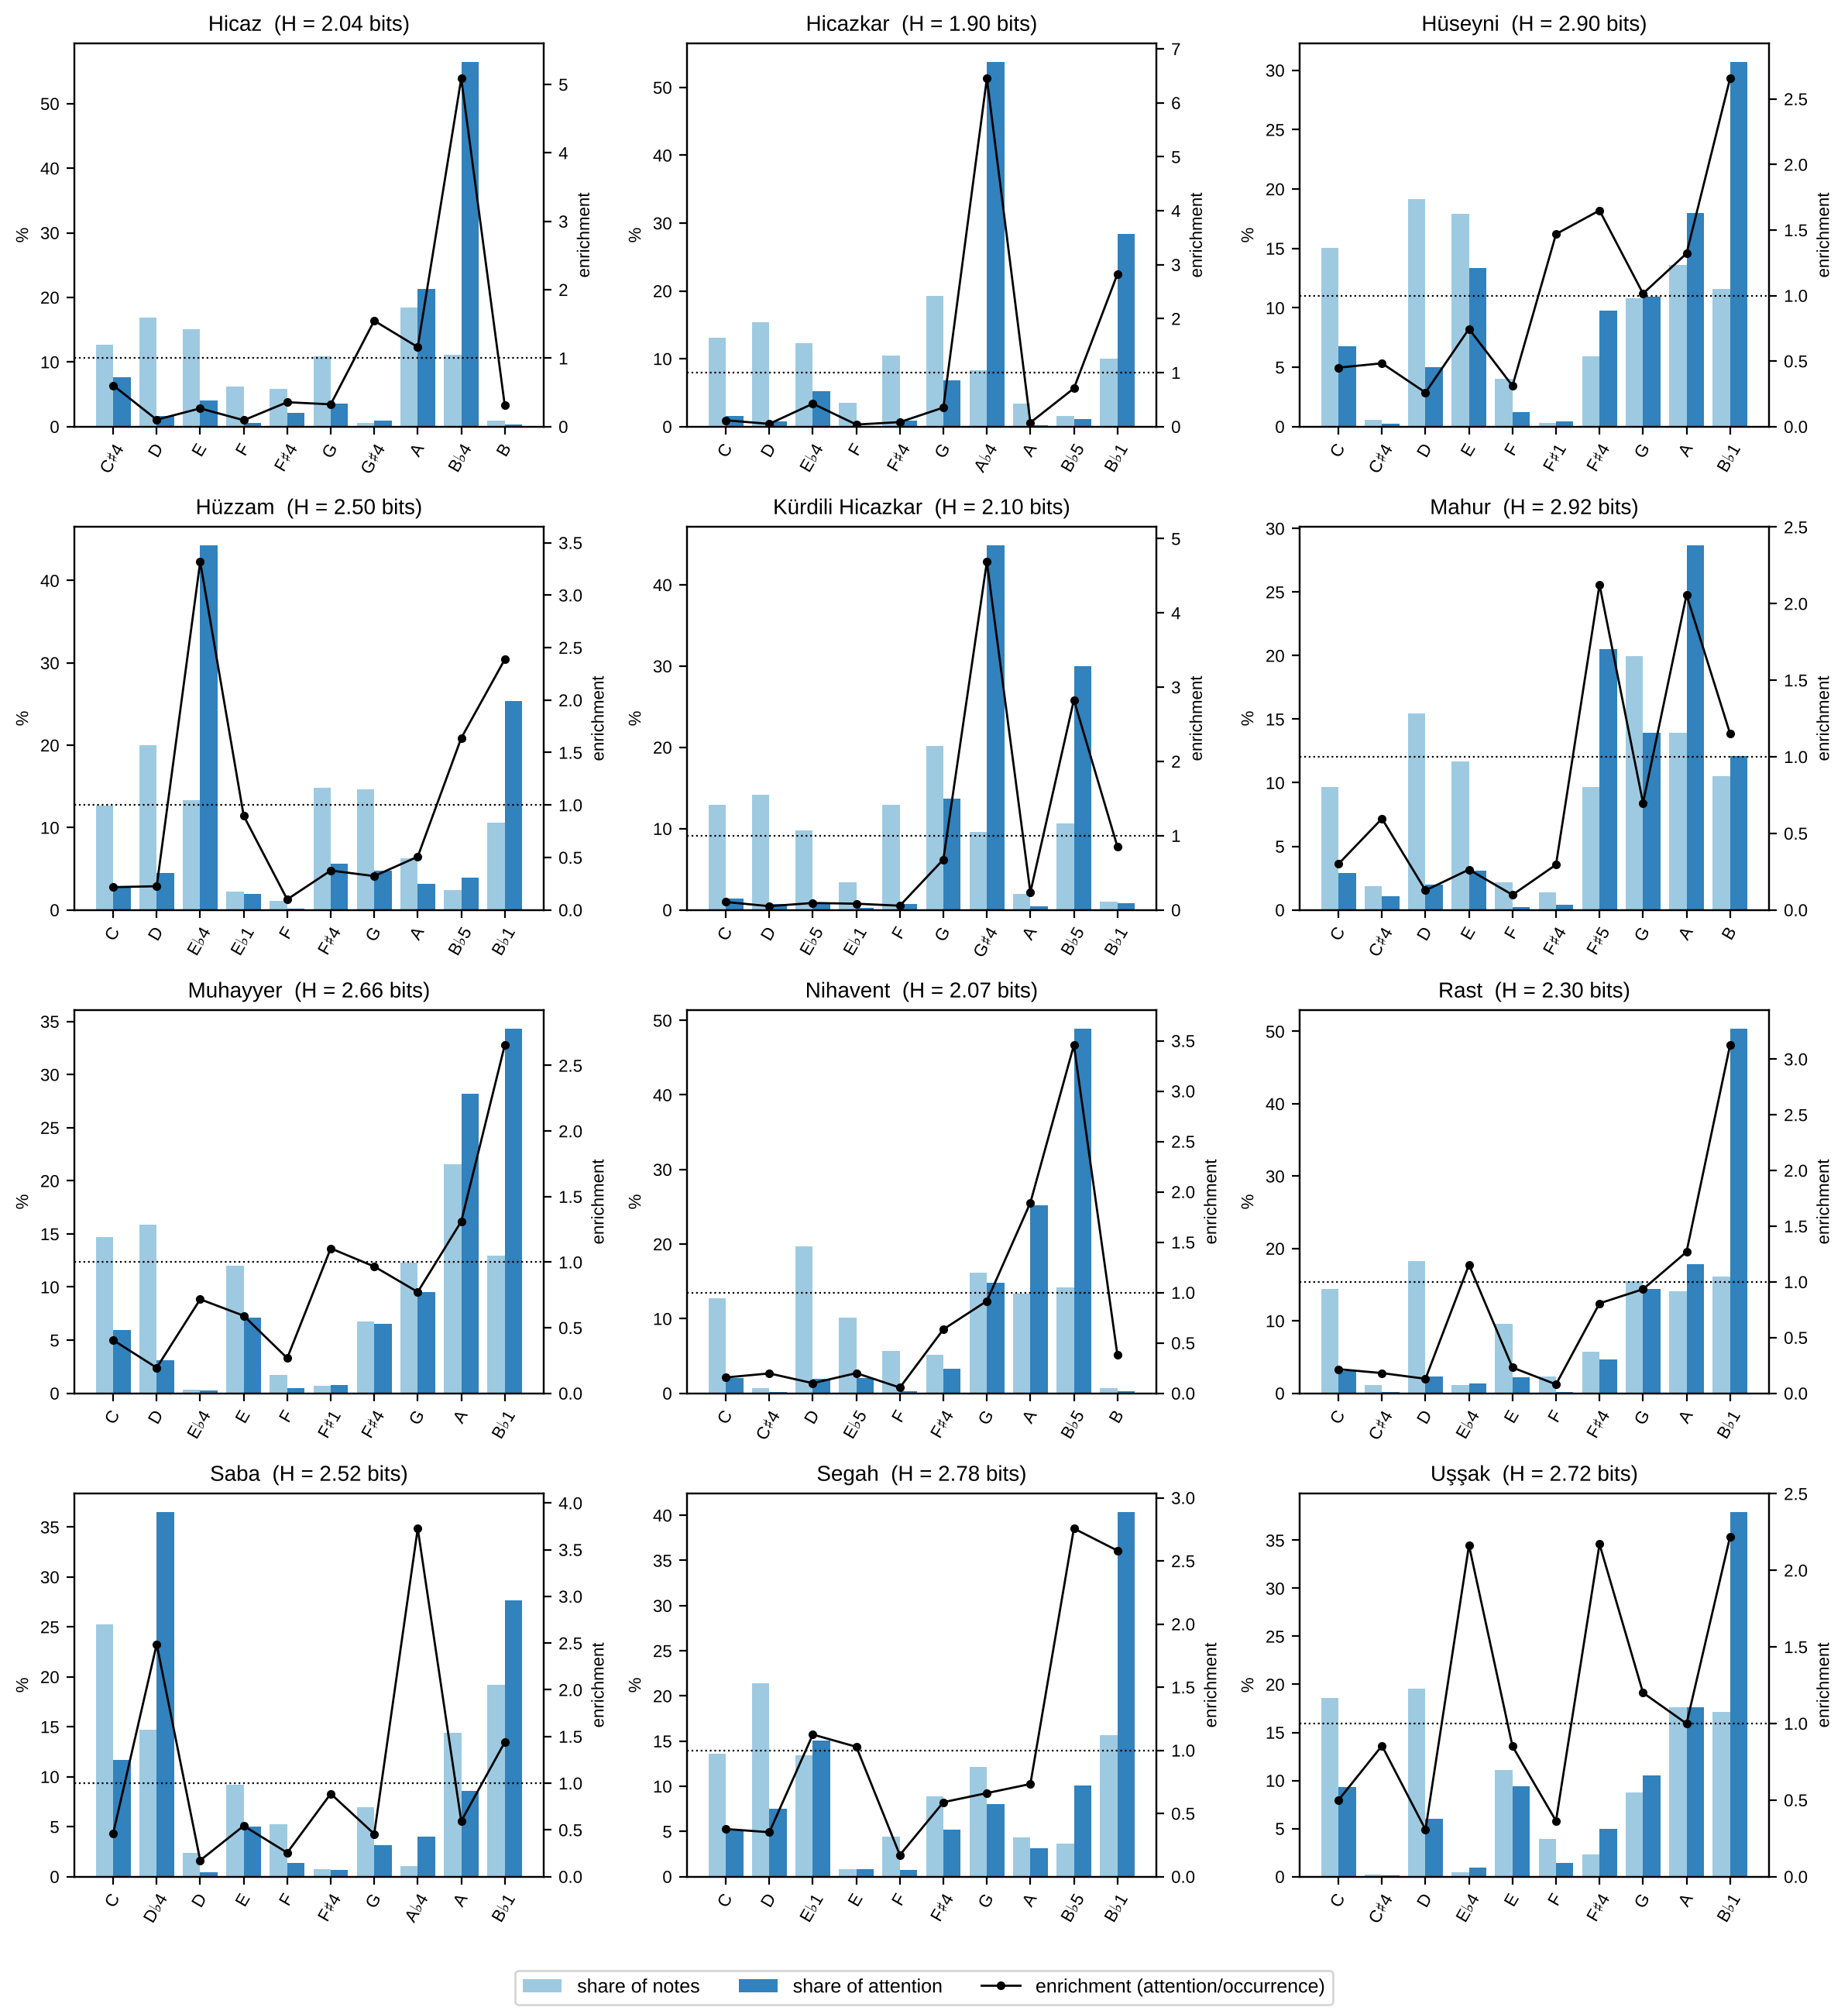

In [17]:
pm.plot_pitch_enrichment(enrichment, tag="full", pitch_order=True, save_fig=SAVE_FIGS)

Figure 8: attention over one test piece

hicaz--sarki--duyek--bogazici_sen--alaeddin_yavasca.txt | notes: 296 | predicted: hicaz


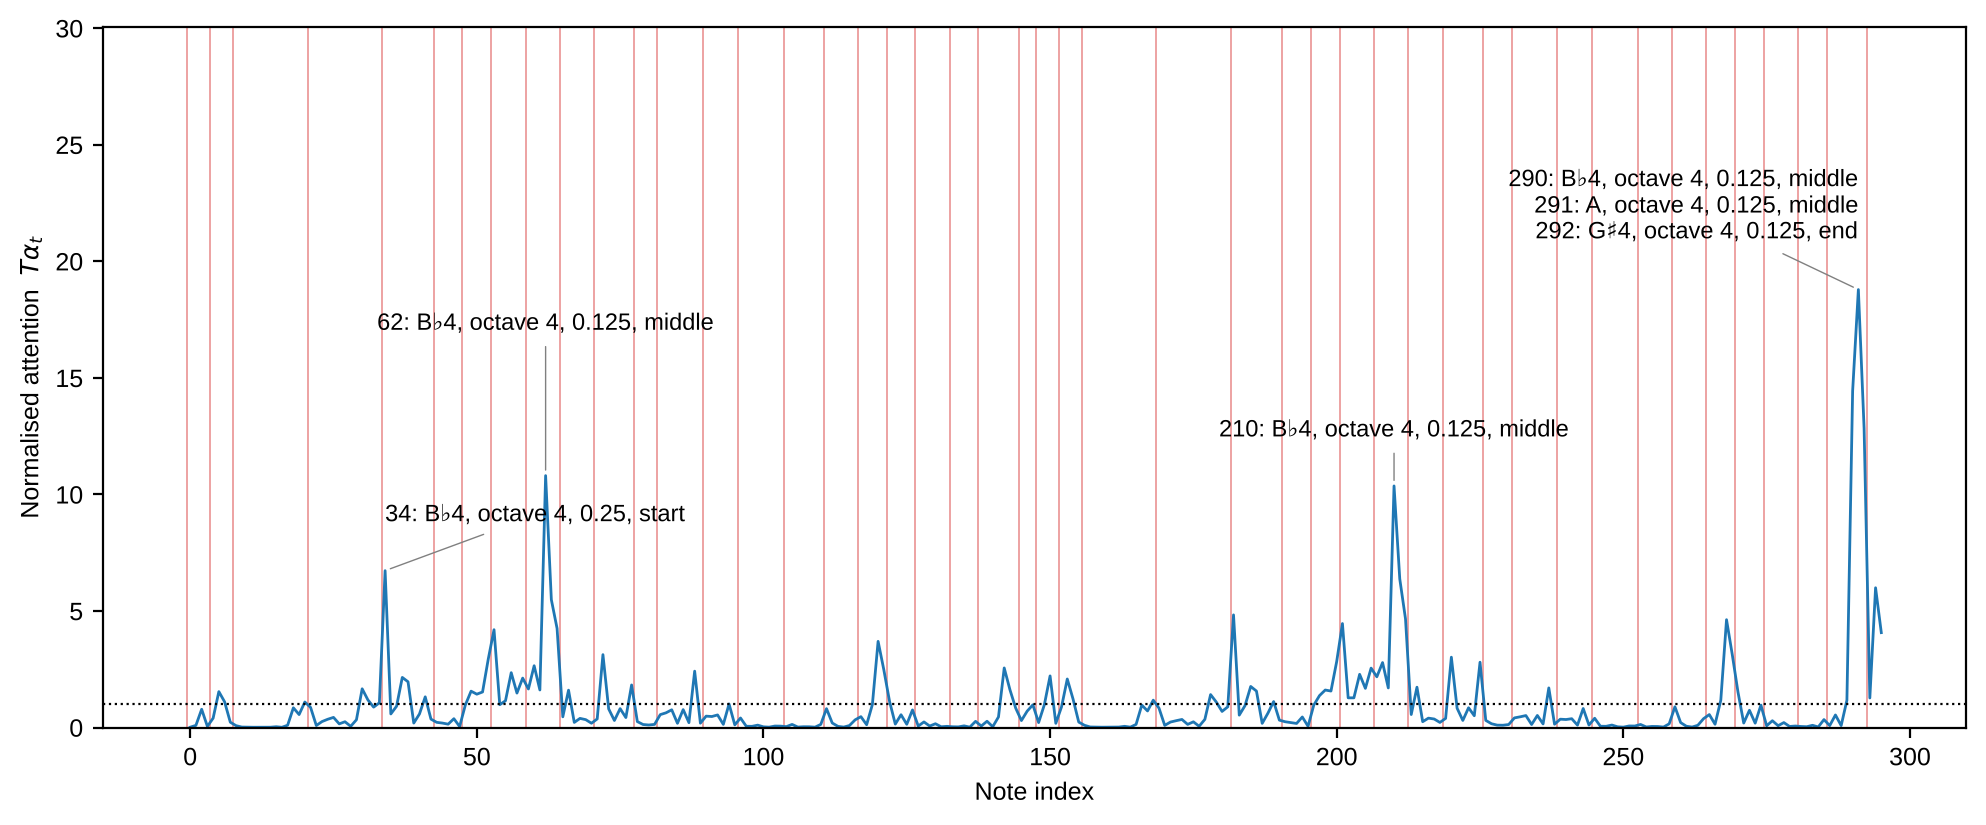

Highest peaks (index: pitch, octave, relative duration, measure position | T*alpha)
  34: Bb4, octave 4, 0.25, start | 6.73
  62: Bb4, octave 4, 0.125, middle | 10.81
  210: Bb4, octave 4, 0.125, middle | 10.36
  290: Bb4, octave 4, 0.125, middle | 14.44
  291: A, octave 4, 0.125, middle | 18.79
  292: G#4, octave 4, 0.125, end | 12.83


In [18]:
piece, attn, predicted_makam = ai.get_piece_attention(
    tag="full",
    seed=EXAMPLE_PIECE_SEED,
    piece_name=EXAMPLE_PIECE
)
print(piece["f_name"], "| notes:", len(attn), "| predicted:", predicted_makam)

pm.plot_example_piece(
    piece["notes"],
    attn,
    dur_values,
    ai.spelling_map,
    save_fig=SAVE_FIGS
)

Figure 9: attention by relative duration (rests left out)

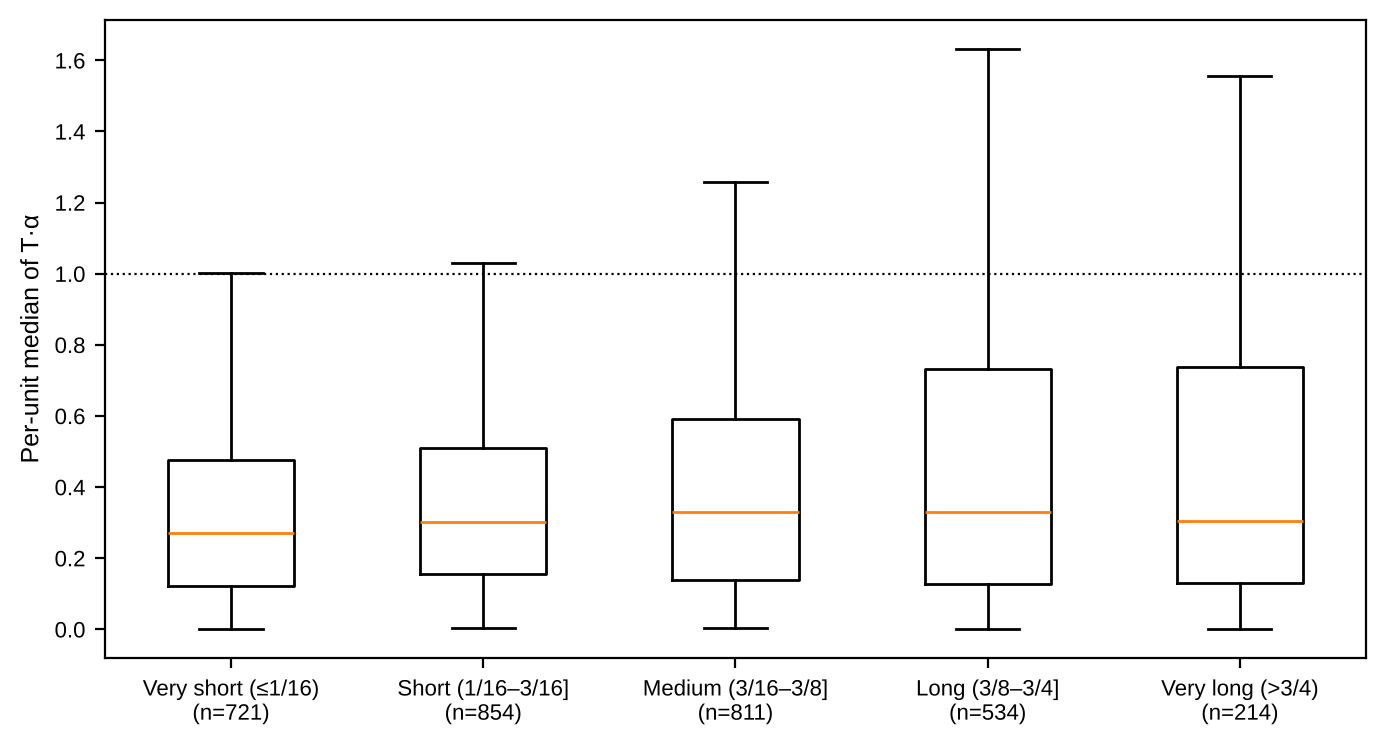

In [19]:
pitched_notes = note_table[~note_table["is_rest"]]
unit_by_duration = ai.unit_by_duration_bin(pitched_notes, "norm_attn")

pm.plot_attention_by_duration(unit_by_duration, tag="full", save_fig=SAVE_FIGS)

Figure 10: attention by position in the measure, for the proposed model and for the model without the measure-position input

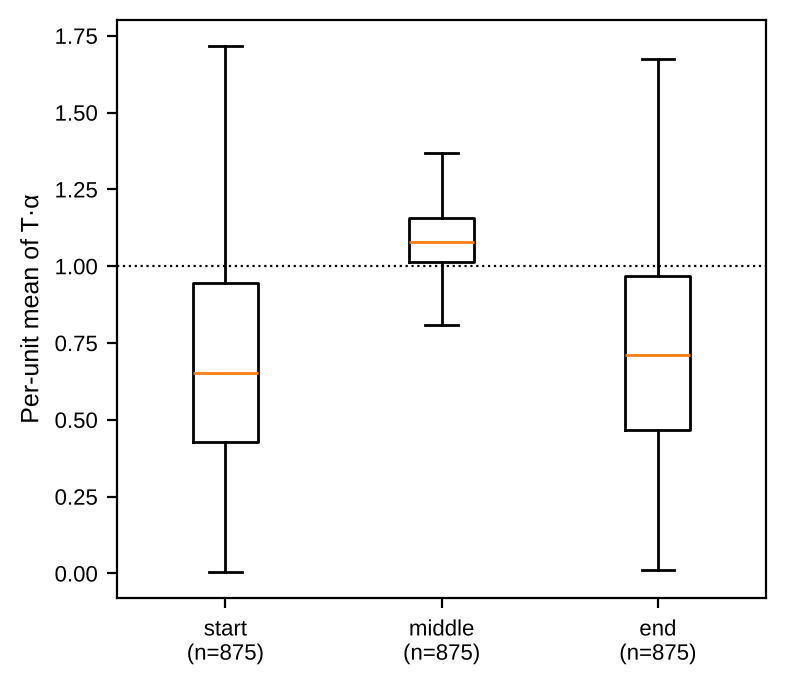

In [20]:
unit_by_position = ai.unit_by_measure_position(note_table, "norm_attn")
pm.plot_attention_by_measure_position(unit_by_position, tag="full", save_fig=SAVE_FIGS)

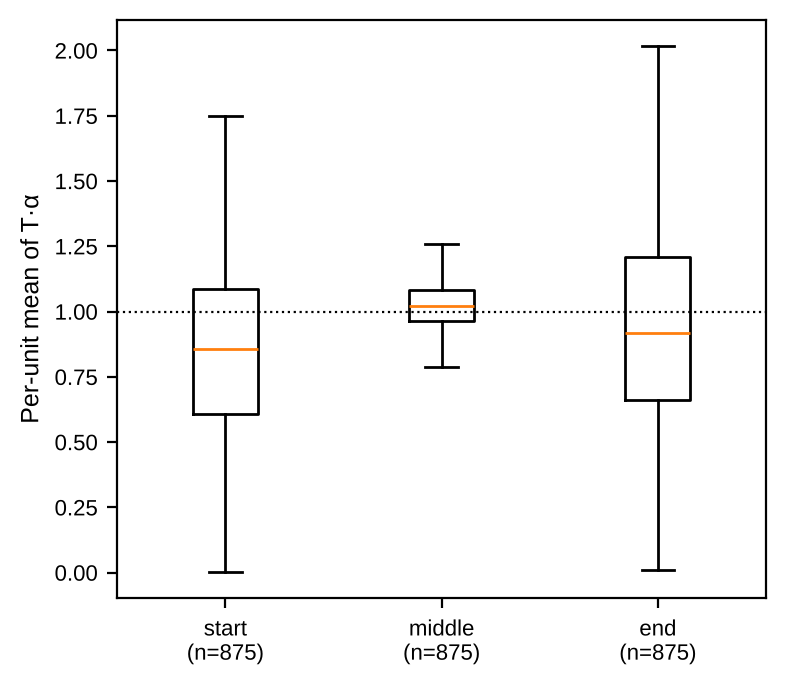

In [21]:
note_table_no_meas = ai.load_note_table("no_meas")
unit_by_position_no_meas = ai.unit_by_measure_position(note_table_no_meas, "norm_attn")
pm.plot_attention_by_measure_position(unit_by_position_no_meas, tag="no_meas", save_fig=SAVE_FIGS)